In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [8]:
decJan25 = pd.read_csv('/Users/lilyrippeteau/Library/CloudStorage/OneDrive-WesternWashingtonUniversity/Shortcuts/WWU Environmental Hydrodynamics Lab - General/Atmospheric Rivers/clam_garden_files/COMBINED_SDT_DEC4-2025_JAN4-2026.csv')
decJan25.head()

,TIME,SITE_NAME,SAL_PSU,DEPTH_M,VERTICAL_POSITION_M,PRESSURE_PSI_A,TEMP_C,MONTH,DAY,YEAR
0,10:30:00 PM,CGS,0.01,-0.188,-0.188,-0.266,7.287,1,4,2026
1,10:20:00 PM,CGS,0.18,-0.188,-0.187,-0.267,8.582,1,4,2026
2,10:10:00 PM,CGS,20.50,-0.105,-0.102,-0.152,8.635,1,4,2026
3,10:00:00 PM,CGS,20.44,0.019,0.018,0.027,8.719,1,4,2026
4,9:50:00 PM,CGS,23.10,0.166,0.163,0.240,9.102,1,4,2026


In [ ]:
#make datetime column
decJan25['DATETIME'] = pd.to_datetime(decJan25['YEAR'].astype(str) + '-' + decJan25['MONTH'].astype(str) + '-' + decJan25['DAY'].astype(str) + ' ' + decJan25['TIME'].astype(str), format='%Y-%m-%d %I:%M:%S %p')

In [ ]:
#reorder the dataframe oldest to most recent
decJan25 = decJan25.sort_values('DATETIME').reset_index(drop=True)

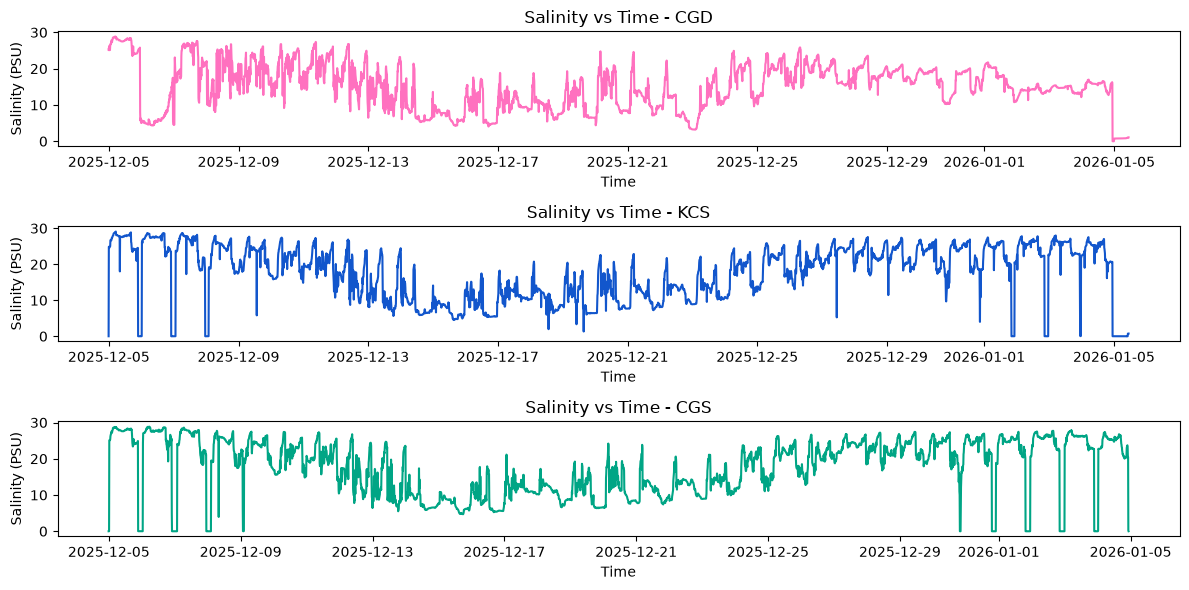

In [41]:
# Plot salinity vs time for each site
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(12, 6))
colors = ['#ff71bf', '#1256cc', '#00a585']

for i, site in enumerate(decJan25['SITE_NAME'].unique()):
    siteData = decJan25[decJan25['SITE_NAME'] == site]
    ax[i].plot(siteData['DATETIME'], siteData['SAL_PSU'], label=site, color=colors[i])
    ax[i].set_xlabel('Time')
    ax[i].set_ylabel('Salinity (PSU)')
    ax[i].set_title(f'Salinity vs Time - {site}')
plt.tight_layout()
plt.show()


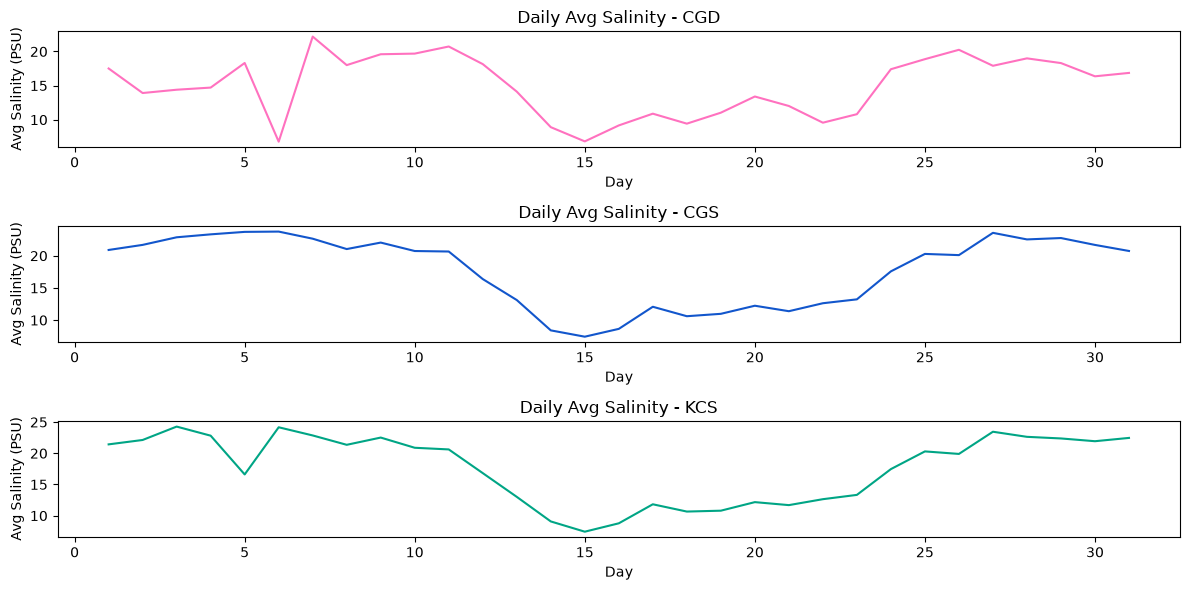

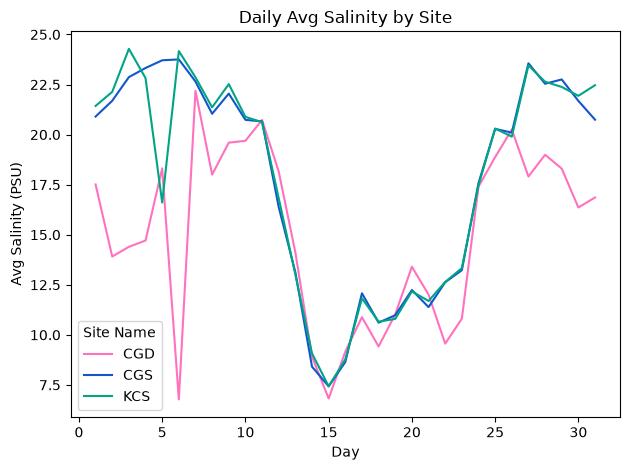

In [40]:
#plot average daily salinity for each site
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(12, 6))
colors = ['#ff71bf', '#1256cc', '#00a585']

dailyAvg = (decJan25.groupby(["SITE_NAME", "DAY"])["SAL_PSU"].mean().reset_index())
sites = dailyAvg["SITE_NAME"].unique()

for i, site in enumerate(sites):
    siteData = dailyAvg[dailyAvg["SITE_NAME"] == site]
    ax[i].plot(siteData["DAY"], siteData["SAL_PSU"], color=colors[i])
    ax[i].set_xlabel("Day")
    ax[i].set_ylabel("Avg Salinity (PSU)")
    ax[i].set_title(f"Daily Avg Salinity - {site}")
plt.tight_layout()
plt.show()

for i, site in enumerate(sites):
    siteData = dailyAvg[dailyAvg["SITE_NAME"] == site]
    plt.plot(siteData["DAY"], siteData["SAL_PSU"], color=colors[i], label=site)
plt.xlabel("Day")
plt.ylabel("Avg Salinity (PSU)")
plt.title("Daily Avg Salinity by Site")
plt.legend(title="Site Name")
plt.tight_layout()
plt.show()


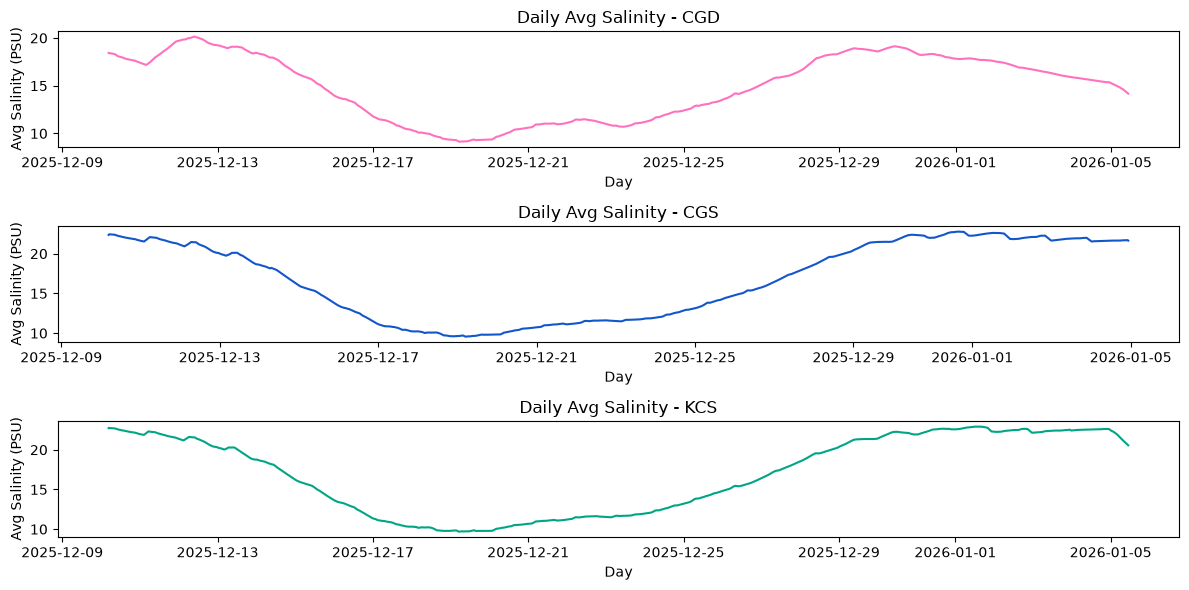

In [44]:
#plot rolling average of salinity for each site
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(12, 6))
colors = ['#ff71bf', '#1256cc', '#00a585']

for i, site in enumerate(sites):
    siteData = decJan25[decJan25["SITE_NAME"] == site]
    rollingAvg = siteData["SAL_PSU"].rolling(window=750).mean()
    ax[i].plot(siteData['DATETIME'], rollingAvg, label=site, color=colors[i])
    ax[i].set_xlabel("Day")
    ax[i].set_ylabel("Avg Salinity (PSU)")
    ax[i].set_title(f"Daily Avg Salinity - {site}")
plt.tight_layout()
plt.show()